In [32]:
import pandas as pd
import numpy as np

data = {
    'Order_ID': range(1001, 1021),

    'Order_Date': [
        '2026-10-01','2026-10-01','2026-10-01',
        '2026-10-01','2026-10-02','2026-10-02',
        '2026-10-02','2026-10-02','2026-10-03',
        '2026-10-03','2026-10-03','2026-10-03',
        '2026-10-04','2026-10-04','2026-10-04',
        '2026-10-04','2026-10-05','2026-10-05',
        '2026-10-05','2026-10-05'
    ],

    'Order_Time': [
        '12:30','13:15','19:00','20:15',
        '12:00','13:30','18:45','21:00',
        '11:45','14:00','19:30','20:45',
        '12:15','13:00','18:30','21:15',
        '12:45','14:30','19:15','20:30'
    ],

    'Restaurant': [
        'Food Hub','Spicy Kitchen','Food Hub','Pizza Point',
        'Spicy Kitchen','Food Hub','Pizza Point','Food Hub',
        'Pizza Point','Spicy Kitchen','Food Hub','Pizza Point',
        'Food Hub','Spicy Kitchen','Pizza Point','Food Hub',
        'Spicy Kitchen','Food Hub','Pizza Point','Food Hub'
    ],

    'City': [
        'Hyderabad','Hyderabad','Hyderabad','Bangalore',
        'Hyderabad','Bangalore','Hyderabad','Hyderabad',
        'Bangalore','Hyderabad','Hyderabad','Bangalore',
        'Hyderabad','Bangalore','Hyderabad','Hyderabad',
        'Bangalore','Hyderabad','Bangalore','Hyderabad'
    ],

    'Order_Value': [
        250, 350, 450, 500, 300, 400, 550, 200,
        600, 250, 350, 450, 300, 500, 650, 250,
        400, 350, 550, 300
    ],

    'Delivery_Time': [
        30, 45, 55, 40, 35, 60, 50, 25,
        70, 40, 35, 65, 30, 55, 45, 80,
        40, 35, 60, 30
    ],

    'Expected_Time': [
        35, 40, 40, 45, 40, 45, 40, 30,
        45, 40, 40, 45, 35, 45, 40, 45,
        40, 40, 45, 35
    ],

    'Customer_Rating': [
        4.5, 3.5, 2.5, 4.0, 4.5, 2.0, 3.0,
        5.0, 2.0, 4.0, 4.5, 2.5, 4.5, 3.0,
        4.0, 1.5, 4.0, 4.5, 3.0, 5.0
    ],

    'Order_Status': [
        'Delivered','Delivered','Delivered','Delivered',
        'Delivered','Delivered','Delivered','Delivered',
        'Delivered','Delivered','Delivered','Cancelled',
        'Delivered','Delivered','Delivered','Cancelled',
        'Delivered','Delivered','Delivered','Delivered'
    ],

    'Payment_Mode': [
        'UPI','Card','UPI','Cash','UPI','Card','UPI',
        'Cash','Card','UPI','UPI','Card','Cash','UPI',
        'Card','UPI','Cash','UPI','Card','UPI'
    ]
}

df = pd.DataFrame(data)

# Add intentional data quality issues
df.loc[2, 'Customer_Rating'] = np.nan
df.loc[5, 'Restaurant'] = np.nan

# Add one duplicate record
df = pd.concat([df, df.iloc[[0]]], ignore_index=True)

(df.head())


,Order_ID,Order_Date,Order_Time,Restaurant,City,Order_Value,Delivery_Time,Expected_Time,Customer_Rating,Order_Status,Payment_Mode
0,1001,2026-10-01,12:30,Food Hub,Hyderabad,250,30,35,4.5,Delivered,UPI
1,1002,2026-10-01,13:15,Spicy Kitchen,Hyderabad,350,45,40,3.5,Delivered,Card
2,1003,2026-10-01,19:00,Food Hub,Hyderabad,450,55,40,NaN,Delivered,UPI
3,1004,2026-10-01,20:15,Pizza Point,Bangalore,500,40,45,4.0,Delivered,Cash
4,1005,2026-10-02,12:00,Spicy Kitchen,Hyderabad,300,35,40,4.5,Delivered,UPI


## Data inspection and cleaning

In [33]:
# Dataset information
print(df.shape)
print(df.info())
print(df.isnull().sum())
print("Duplicate rows:", df.duplicated().sum())

(21, 11)
<class 'pandas.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Order_ID         21 non-null     int64  
 1   Order_Date       21 non-null     str    
 2   Order_Time       21 non-null     str    
 3   Restaurant       20 non-null     str    
 4   City             21 non-null     str    
 5   Order_Value      21 non-null     int64  
 6   Delivery_Time    21 non-null     int64  
 7   Expected_Time    21 non-null     int64  
 8   Customer_Rating  20 non-null     float64
 9   Order_Status     21 non-null     str    
 10  Payment_Mode     21 non-null     str    
dtypes: float64(1), int64(4), str(6)
memory usage: 2.9 KB
None
Order_ID           0
Order_Date         0
Order_Time         0
Restaurant         1
City               0
Order_Value        0
Delivery_Time      0
Expected_Time      0
Customer_Rating    1
Order_Status       0
Payment_Mode       0
dtype: 

In [34]:
# remove duplicates
df = df.drop_duplicates()
print("After removing duplicates:", df.shape)

After removing duplicates: (20, 11)


In [35]:
# handle missing values
df['Restaurant'] = df['Restaurant'].fillna('Unknown')
df['Customer_Rating'] = df['Customer_Rating'].fillna(
    df['Customer_Rating'].median()
)
print(df.isnull().sum().sum())

0


In [36]:
# convert date and time columns
df['Order_Date'] = pd.to_datetime(df['Order_Date'])

df['Order_Time'] = pd.to_datetime(df['Order_Time'], format='%H:%M').dt.time

print(df.dtypes)

Order_ID                    int64
Order_Date         datetime64[us]
Order_Time                 object
Restaurant                    str
City                          str
Order_Value                 int64
Delivery_Time               int64
Expected_Time               int64
Customer_Rating           float64
Order_Status                  str
Payment_Mode                  str
dtype: object


In [37]:
# calaculate delivery delay
df['Delivery_Delay'] = (df['Delivery_Time'] - df['Expected_Time'])
df['Delivery_Status'] = np.where( df['Delivery_Delay'] > 0,'Delayed','On Time')
(df[['Order_ID', 'Delivery_Delay', 'Delivery_Status']].head(10))

,Order_ID,Delivery_Delay,Delivery_Status
0,1001,-5,On Time
1,1002,5,Delayed
2,1003,15,Delayed
3,1004,-5,On Time
4,1005,-5,On Time
5,1006,15,Delayed
6,1007,10,Delayed
7,1008,-5,On Time
8,1009,25,Delayed
9,1010,0,On Time


In [55]:
# extracting ordering hours
df['Order_Hour'] = pd.to_datetime(df['Order_Time'], format='%H:%M:%S').dt.hour
(df[['Order_Time', 'Order_Hour']].head())


,Order_Time,Order_Hour
0,12:30:00,12
1,13:15:00,13
2,19:00:00,19
3,20:15:00,20
4,12:00:00,12


In [44]:
df['Delivery_Category'] = pd.cut(
    df['Delivery_Time'],
    bins=[0, 30, 45, 60, float('inf')],
    labels=['Fast', 'Normal', 'Slow', 'Very Slow']
)
print(df['Delivery_Category'].value_counts())

Delivery_Category
Normal       8
Slow         5
Fast         4
Very Slow    3
Name: count, dtype: int64


## What percentage of orders were cancelled?

In [54]:
status_count = df['Order_Status'].value_counts()
cancellation_rate = (df['Order_Status'].eq('Cancelled').mean() * 100)
print(status_count)
("Cancellation Rate:", cancellation_rate)

Order_Status
Delivered    18
Cancelled     2
Name: count, dtype: int64


('Cancellation Rate:', np.float64(10.0))

In [53]:
# Which restaurant has the highest order value?
restaurant_analysis = ( df.groupby('Restaurant').agg(Total_Orders=('Order_ID', 'count'),Total_Revenue=('Order_Value', 'sum'))
      .sort_values('Total_Revenue', ascending=False))
(restaurant_analysis)

,Total_Orders,Total_Revenue
Restaurant,,
Pizza Point,6,3300
Food Hub,8,2450
Spicy Kitchen,5,1800
Unknown,1,400


In [52]:
# Which restaurant has the highest delivery time?
delivered = df[df['Order_Status'] == 'Delivered']

restaurant_performance = (
    delivered.groupby('Restaurant')
    .agg(
        Total_Orders=('Order_ID', 'count'),
        Avg_Delivery_Time=('Delivery_Time', 'mean'),
        Avg_Rating=('Customer_Rating', 'mean'),
        Revenue=('Order_Value', 'sum')
    )
    .round(2)
)
(restaurant_performance)

,Total_Orders,Avg_Delivery_Time,Avg_Rating,Revenue
Restaurant,,,,
Food Hub,7,34.29,4.57,2200
Pizza Point,5,53.00,3.20,2850
Spicy Kitchen,5,43.00,3.80,1800
Unknown,1,60.00,2.00,400


In [56]:
# When do customers place the most orders?
hourly_orders = df.groupby('Order_Hour').agg(Total_Orders=('Order_ID', 'count'))
(hourly_orders)

,Total_Orders
Order_Hour,
11,1
12,4
13,3
14,2
18,2
19,3
20,3
21,2


In [57]:
# Which city has better delivery performance?
city_analysis = (
    delivered.groupby('City')
    .agg(
        Total_Orders=('Order_ID', 'count'),
        Avg_Delivery_Time=('Delivery_Time', 'mean'),
        Revenue=('Order_Value', 'sum')
    )
    .round(2)
)
(city_analysis)

,Total_Orders,Avg_Delivery_Time,Revenue
City,,,
Bangalore,6,54.17,2950
Hyderabad,12,37.92,4300


In [61]:
# How many orders were delivered late?
delivered = df[df['Order_Status'] == 'Delivered']
late_orders = delivered[
    delivered['Delivery_Delay'] > 0]
late_percentage = (len(late_orders) / len(delivered)) * 100
print("Late Orders:", len(late_orders))

print("Late Delivery Percentage:", round(late_percentage, 2))

Late Orders: 8
Late Delivery Percentage: 44.44


In [62]:
#What is the average customer rating?
average_rating = delivered['Customer_Rating'].mean()

print("Average Customer Rating:",
      round(average_rating, 2))

Average Customer Rating: 3.83


In [64]:
pivot = pd.pivot_table(
    delivered,
    values='Order_Value',
    index='Restaurant',
    columns='City',
    aggfunc='sum',
    fill_value=0
)
(pivot)

City,Bangalore,Hyderabad
Restaurant,,
Food Hub,0,2200
Pizza Point,1650,1200
Spicy Kitchen,900,900
Unknown,400,0


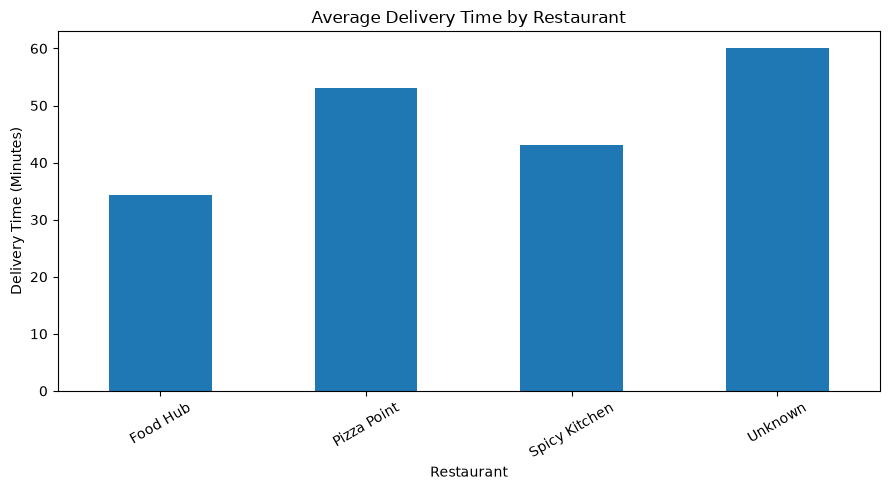

In [66]:
# Restaurant-wise average delivery time
import matplotlib.pyplot as plt

restaurant_performance[
    'Avg_Delivery_Time'
].plot(
    kind='bar',
    figsize=(9, 5),
    title='Average Delivery Time by Restaurant'
)

plt.ylabel('Delivery Time (Minutes)')
plt.xlabel('Restaurant')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

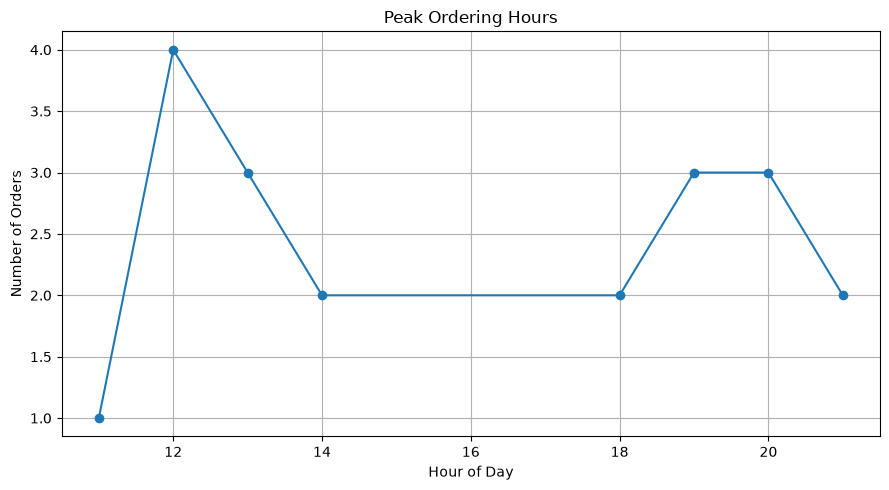

In [69]:
#Order distribution by hour
hourly_orders['Total_Orders'].plot(
    kind='line',
    marker='o',
    figsize=(9, 5),
    title='Peak Ordering Hours'
)

plt.xlabel('Hour of Day')
plt.ylabel('Number of Orders')
plt.grid(True)
plt.tight_layout()
plt.show()

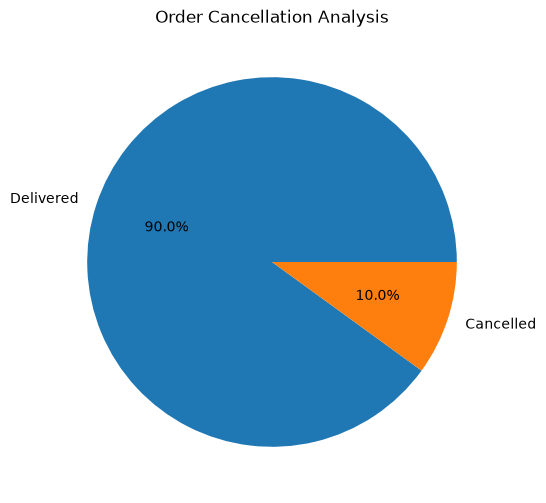

In [77]:
# cancelation analysis
df['Order_Status'].value_counts().plot(
    kind='pie',
    autopct='%1.1f%%',
    figsize=(6, 6),
    title='Order Cancellation Analysis'
)

plt.ylabel('')
plt.show()